In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs("images", exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
if not os.path.exists("advertising.csv"):
    raise FileNotFoundError(
        "advertising.csv was not found. Put advertising.csv in the same folder as this notebook."
    )

df = pd.read_csv("advertising.csv")

if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully.
Shape: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [3]:
print("Last 5 rows:")
display(df.tail())

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Last 5 rows:


,TV,Radio,Newspaper,Sales
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5
199,232.1,8.6,8.7,13.4


Shape: (200, 4)

Columns:
['TV', 'Radio', 'Newspaper', 'Sales']

Data types:
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0


In [4]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print("\nStatistical summary:")
display(df.describe())

Shape after removing duplicates: (200, 4)

Statistical summary:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [5]:
features = ["TV", "Radio", "Newspaper"]

required_columns = features + ["Sales"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

X = df[features]
y = df["Sales"]

print("Input features:")
display(X.head())

print("Target variable:")
display(y.head())

Input features:


,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


Target variable:


0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: Sales, dtype: float64

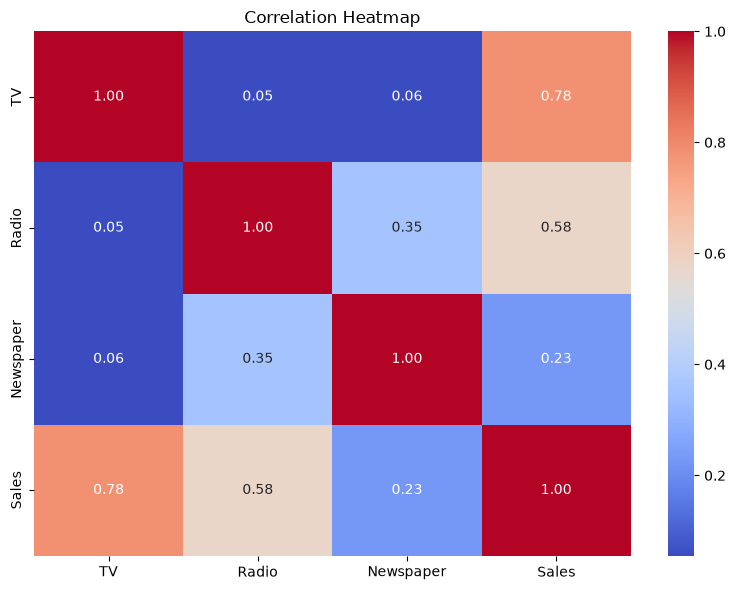

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[required_columns].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("images/heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

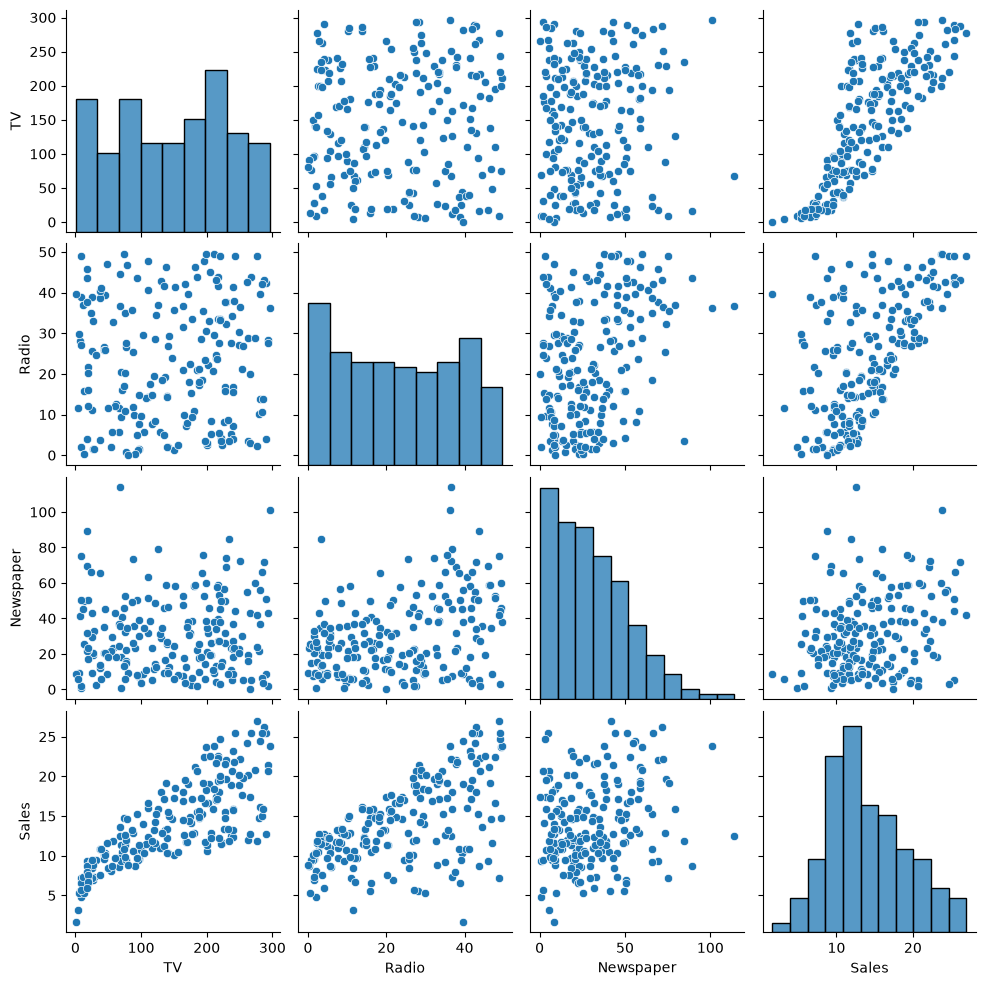

In [7]:
sns.pairplot(df[required_columns])
plt.savefig("images/pair_plot.png", dpi=300, bbox_inches="tight")
plt.show()

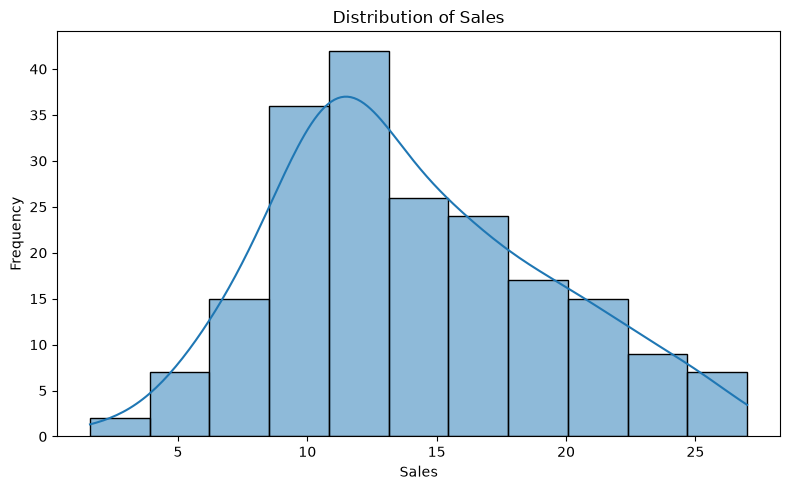

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Sales"], kde=True)
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.title("Distribution of Sales")
plt.tight_layout()
plt.savefig("images/sales_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

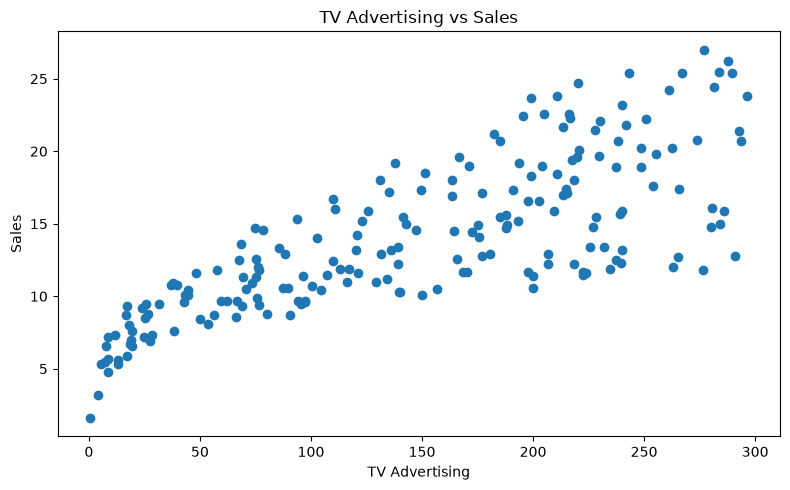

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df["TV"], df["Sales"])
plt.xlabel("TV Advertising")
plt.ylabel("Sales")
plt.title("TV Advertising vs Sales")
plt.tight_layout()
plt.savefig("images/scatter_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160
Testing samples: 40


In [11]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully.")
print("Intercept:", model.intercept_)

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})
display(coefficients)

Model trained successfully.
Intercept: 2.979067338122629


,Feature,Coefficient
0,TV,0.044730
1,Radio,0.189195
2,Newspaper,0.002761


In [12]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326 13.10559172
 21.05719192  7.46101034 13.60634581 15.15506967]


In [13]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 1.4608
Mean Squared Error (MSE): 3.1741
Root Mean Squared Error (RMSE): 1.7816
R² Score: 0.8994


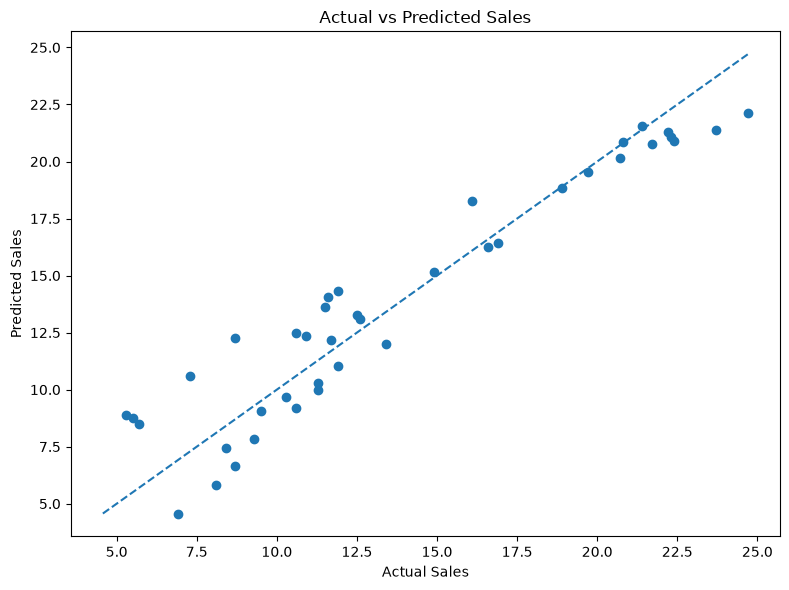

In [14]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

plt.tight_layout()
plt.savefig("images/actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
new_data = pd.DataFrame({
    "TV": [150],
    "Radio": [25],
    "Newspaper": [30]
})

prediction = model.predict(new_data)

print(f"Predicted Sales: {prediction[0]:.2f}")

Predicted Sales: 14.50


In [16]:
print("Generated files in the images folder:")
for file in sorted(os.listdir("images")):
    print("-", file)

Generated files in the images folder:
- actual_vs_predicted.png
- heatmap.png
- pair_plot.png
- sales_distribution.png
- scatter_plot.png
